In [4]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning
!pip install pennylane scikit-learn matplotlib
!pip install qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 3.6 MB/s eta 0:00:00


STEP 2. Parameterized Quantum Circuit & Simulator
Target : -0.8


STEP 4. SPSA History & Objective


STEP 5. Initial Parameter
Initial Parameter  : 0.2
Initial Prediction : 0.98046875
Initial Loss       : 3.1700689697265627


STEP 6. SPSA


STEP 7. Optimization
[001] Theta=  0.0000 Prediction=  1.0000 Loss=  3.240000
[002] Theta=  0.4000 Prediction=  0.9092 Loss=  2.921295
[003] Theta=  0.4000 Prediction=  0.9316 Loss=  2.998579
[004] Theta=  0.0000 Prediction=  1.0000 Loss=  3.240000
[005] Theta=  0.0000 Prediction=  1.0000 Loss=  3.240000
[006] Theta=  0.4000 Prediction=  0.9229 Loss=  2.968218
[007] Theta=  0.4000 Prediction=  0.9082 Loss=  2.917958
[008] Theta=  0.0000 Prediction=  1.0000 Loss=  3.240000
[009] Theta=  0.4000 Prediction=  0.9170 Loss=  2.948062
[010] Theta=  0.0000 Prediction=  1.0000 Loss=  3.240000
[011] Theta=  0.4000 Prediction=  0.9160 Loss=  2.944710
[012] Theta=  0.0000 Prediction=  1.0000 Loss=  3.240000
[013] Theta=  0.0000 Prediction=  1.0000 Loss=  3.2400

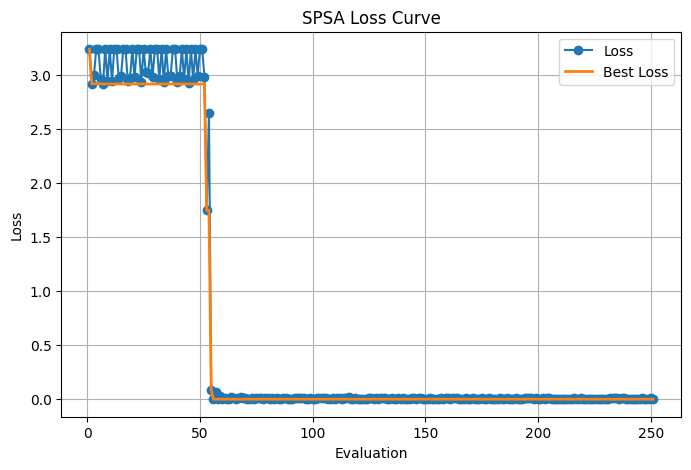

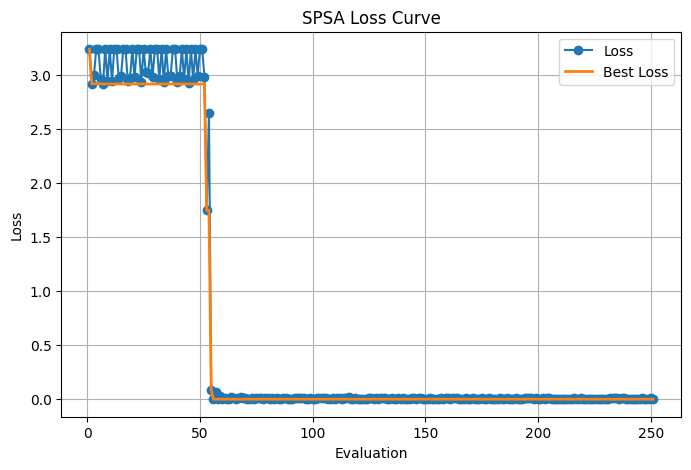

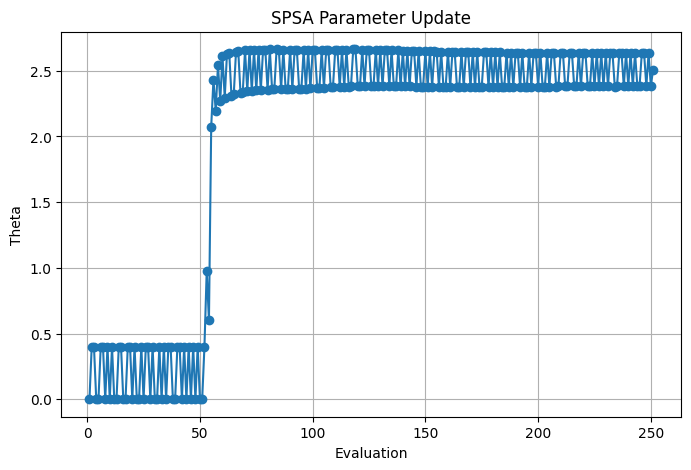

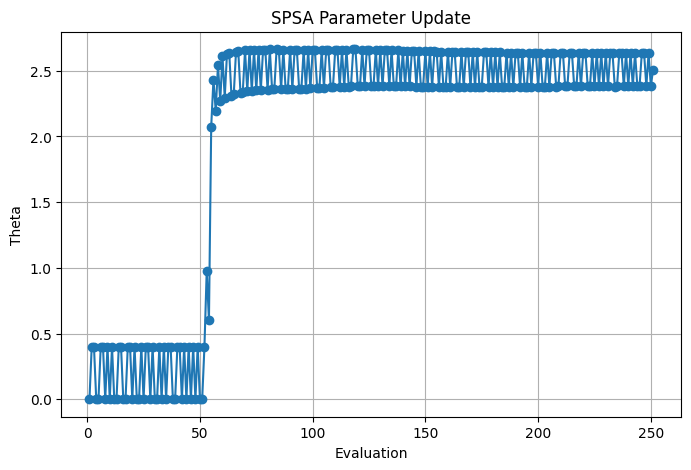

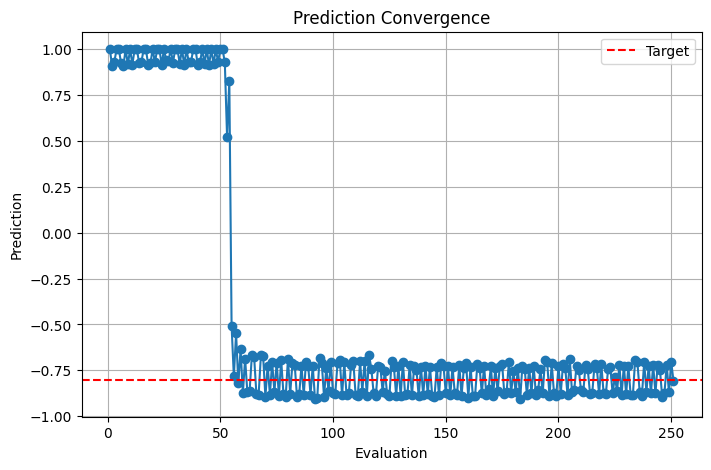

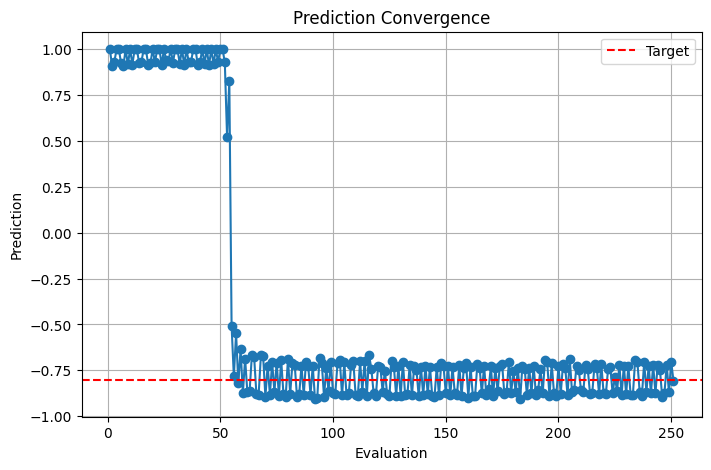

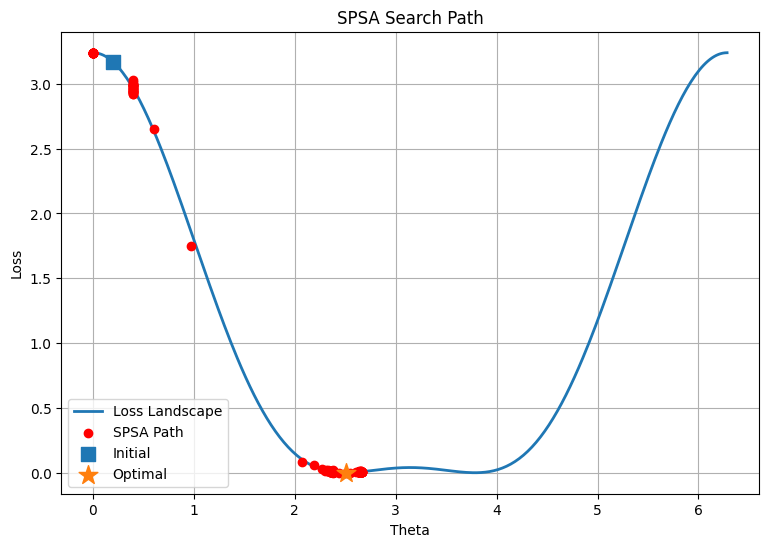

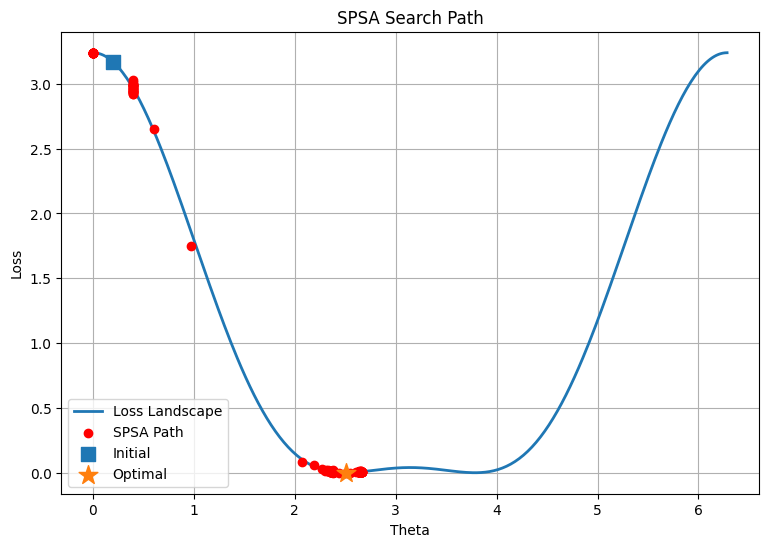



SUMMARY
Initial Parameter   : 0.2
Optimal Parameter   : 2.5093852830649985
Initial Loss        : 3.1700689697265627
Final Loss          : 0.0005401992797851541
Prediction          : -0.8232421875
Function Evaluation : 200
Iteration           : 100

Lab Complete


In [6]:
%matplotlib inline

# ============================================================
# STEP 1. Library Import
# ============================================================

import time
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit import transpile
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_algorithms.optimizers import SPSA

# ============================================================
# STEP 2. Parameterized Quantum Circuit 생성 및 환경 설정
# ============================================================

print("=" * 80)
print("STEP 2. Parameterized Quantum Circuit & Simulator")
print("=" * 80)

theta = Parameter("θ")
qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()

simulator = AerSimulator()
shots = 2048

# ============================================================
# STEP 3. Prediction & Objective Function 구현
# ============================================================

def predict(theta_value):
    bound = qc.assign_parameters({theta: theta_value})
    compiled = transpile(bound, simulator)
    job = simulator.run(compiled, shots=shots)
    result = job.result()
    counts = result.get_counts()

    p0 = counts.get("0", 0) / shots
    p1 = counts.get("1", 0) / shots
    prediction = p0 - p1
    return prediction

target = -0.8
print("Target :", target)

# ============================================================
# STEP 4. SPSA History & Objective Function
# ============================================================

print("\n")
print("=" * 80)
print("STEP 4. SPSA History & Objective")
print("=" * 80)

spsa_history = {
    "evaluation": [],
    "parameter": [],
    "prediction": [],
    "loss": [],
    "best_loss": []
}

def spsa_objective(parameters):
    theta_value = float(parameters[0])
    prediction = predict(theta_value)
    loss = (prediction - target) ** 2

    evaluation = len(spsa_history["evaluation"]) + 1

    spsa_history["evaluation"].append(evaluation)
    spsa_history["parameter"].append(theta_value)
    spsa_history["prediction"].append(prediction)
    spsa_history["loss"].append(loss)

    current_best = min(spsa_history["loss"])
    spsa_history["best_loss"].append(current_best)

    print(
        f"[{evaluation:03d}] "
        f"Theta={theta_value:8.4f} "
        f"Prediction={prediction:8.4f} "
        f"Loss={loss:10.6f}"
    )

    return float(loss)

# ============================================================
# STEP 5. Initial Parameter
# ============================================================

print("\n")
print("=" * 80)
print("STEP 5. Initial Parameter")
print("=" * 80)

initial_point = np.array([0.2])
initial_prediction = predict(initial_point[0])
initial_loss = (initial_prediction - target) ** 2

print("Initial Parameter  :", initial_point[0])
print("Initial Prediction :", initial_prediction)
print("Initial Loss       :", initial_loss)

# ============================================================
# STEP 6. SPSA 생성
# ============================================================

print("\n")
print("=" * 80)
print("STEP 6. SPSA")
print("=" * 80)

optimizer = SPSA(
    maxiter=100
)

print(optimizer)

# ============================================================
# STEP 7. Optimization
# ============================================================

print("\n")
print("=" * 80)
print("STEP 7. Optimization")
print("=" * 80)

start = time.perf_counter()

result = optimizer.minimize(
    fun=spsa_objective,
    x0=initial_point
)

elapsed = time.perf_counter() - start

# ============================================================
# STEP 8. Result
# ============================================================

print("\n")
print("=" * 80)
print("STEP 8. Result")
print("=" * 80)

optimal_theta = float(result.x[0])
optimizer_loss = float(result.fun)
nfev = getattr(result, "nfev", None)
nit = getattr(result, "nit", None)

print("Optimal Theta       :", optimal_theta)
print("Optimizer Loss      :", optimizer_loss)
print("Function Evaluation :", nfev)
print("Iteration           :", nit)
print("Elapsed Time        :", f"{elapsed:.4f} sec")

# ============================================================
# STEP 9. Prediction Verification
# ============================================================

print("\n")
print("=" * 80)
print("STEP 9. Prediction Verification")
print("=" * 80)

final_prediction = predict(optimal_theta)
verified_loss = (final_prediction - target) ** 2

print("Prediction    :", final_prediction)
print("Target        :", target)
print("Verified Loss :", verified_loss)

# ============================================================
# STEP 10. Loss Curve
# ============================================================

fig1 = plt.figure(figsize=(8, 5))

plt.plot(
    spsa_history["evaluation"],
    spsa_history["loss"],
    marker="o",
    label="Loss"
)

plt.plot(
    spsa_history["evaluation"],
    spsa_history["best_loss"],
    linewidth=2,
    label="Best Loss"
)

plt.xlabel("Evaluation")
plt.ylabel("Loss")
plt.title("SPSA Loss Curve")
plt.grid(True)
plt.legend()
display(fig1)
plt.show()

# ============================================================
# STEP 11. Parameter Curve
# ============================================================

fig2 = plt.figure(figsize=(8, 5))

plt.plot(
    spsa_history["evaluation"],
    spsa_history["parameter"],
    marker="o"
)

plt.xlabel("Evaluation")
plt.ylabel("Theta")
plt.title("SPSA Parameter Update")
plt.grid(True)
display(fig2)
plt.show()

# ============================================================
# STEP 12. Prediction Curve
# ============================================================

fig3 = plt.figure(figsize=(8, 5))

plt.plot(
    spsa_history["evaluation"],
    spsa_history["prediction"],
    marker="o"
)

plt.axhline(
    y=target,
    color="red",
    linestyle="--",
    label="Target"
)

plt.xlabel("Evaluation")
plt.ylabel("Prediction")
plt.title("Prediction Convergence")
plt.grid(True)
plt.legend()
display(fig3)
plt.show()

# ============================================================
# STEP 13. Loss Landscape & Search Path
# ============================================================

theta_space = np.linspace(0, 2 * np.pi, 300)
landscape = (np.cos(theta_space) - target) ** 2

fig4 = plt.figure(figsize=(9, 6))

plt.plot(
    theta_space,
    landscape,
    label="Loss Landscape",
    linewidth=2
)

plt.scatter(
    spsa_history["parameter"],
    spsa_history["loss"],
    color="red",
    zorder=5,
    label="SPSA Path"
)

plt.scatter(
    [initial_point[0]],
    [initial_loss],
    marker="s",
    s=100,
    zorder=6,
    label="Initial"
)

plt.scatter(
    [optimal_theta],
    [optimizer_loss],
    marker="*",
    s=200,
    zorder=7,
    label="Optimal"
)

plt.xlabel("Theta")
plt.ylabel("Loss")
plt.title("SPSA Search Path")
plt.grid(True)
plt.legend()
display(fig4)
plt.show()

# ============================================================
# STEP 14. Summary
# ============================================================

print("\n")
print("=" * 80)
print("SUMMARY")
print("=" * 80)

print("Initial Parameter   :", initial_point[0])
print("Optimal Parameter   :", optimal_theta)
print("Initial Loss        :", initial_loss)
print("Final Loss          :", verified_loss)
print("Prediction          :", final_prediction)
print("Function Evaluation :", nfev)
print("Iteration           :", nit)

print("\n" + "=" * 80)
print("Lab Complete")
print("=" * 80)